# 📊 Lecture 6 Activity Notebook: Data Visualization
## AA640: Data Analytics and Text Mining
### Bryant University | Prof. Gianluca Brero

---

**IMPORTANT:** *Before starting, save a copy to your Drive via `File > "Save a copy in Drive"`*

### 🎯 Estimated Time: 90 Minutes

#### In-Class Schedule

| Time | Clock | Block |
|------|-------|-------|
| 30 min | 6:30pm | Lecture: Cleaning Pipeline Recap + Matplotlib |
| 20 min | 7:00pm | **Activity 1** — Matplotlib: Line, Bar, Scatter & Histogram |
| 30 min | 7:20pm | Lecture: Seaborn & Combining Plots |
| 30 min | 7:50pm | Break + Quiz |
| 20 min | 8:20pm | **Activity 2** — Build a Dashboard |
| 30 min | 8:40pm | Open time — questions, finish notebook |

#### After-Class Activities (~30 min)
*Complete these on your own after lecture.*

| Activity | Topic | Time |
|----------|-------|------|
| Activity 3 | Seaborn: Box Plot, Histogram & Pair Plot | ~15 min |
| Activity 4 | Scatter Plots & Heatmap | ~15 min |

### ⚙️ How to Use This Notebook
1. **Read** each section carefully
2. **Run** the example cells first to see how things work
3. **Complete** the activities marked with 📝
4. **Check** your answers against the expected output

> 💡 **Tip:** If you get stuck, re-read the example cell right above the activity — the pattern is always there!

## Setup: Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("pandas version:", pd.__version__)
print("Setup complete!")

pandas version: 2.2.2
Setup complete!


---
# 📋 PRE-ACTIVITY: Format & Validate Practice

**Complete this section during open time.** This covers the last two steps of the cleaning pipeline from last lecture.

---

## Part 1: String Cleaning

When a column contains text, you can use `.str.` followed by a method name to clean every value at once — no loops needed:

- **`.str.strip()`** — removes extra spaces from the beginning and end
- **`.str.lower()`** — makes everything lowercase
- **`.str.title()`** — capitalizes the First Letter Of Each Word
- **`.str.replace()`** — replaces characters (like `$` or `%`)

### Demo: Cleaning Messy Names

In [ ]:
# Demo data -- notice the problems: extra spaces, inconsistent capitalization
names = pd.Series(['  alice SMITH  ', 'BOB jones', ' Charlie  Brown', '  diana PRINCE'])
print("Original:")
print(names)
print()

# Step 1: strip() removes spaces from the beginning and end
print("After strip():")
print(names.str.strip())
print()

# Step 2: title() capitalizes first letter of each word
print("After strip().title():")
print(names.str.strip().str.title())
print()

# Step 3: fix extra spaces INSIDE a name (e.g., 'Charlie  Brown' -> 'Charlie Brown')
# Don't worry about the regex -- just copy this line when you need it
names_clean = names.str.strip().str.title().str.replace(r'\s+', ' ', regex=True)
print("Fully cleaned:")
print(names_clean)

Original:
0      alice SMITH  
1          BOB jones
2     Charlie  Brown
3       diana PRINCE
dtype: object

After strip():
0       alice SMITH
1         BOB jones
2    Charlie  Brown
3      diana PRINCE
dtype: object

After strip().title():
0       Alice Smith
1         Bob Jones
2    Charlie  Brown
3      Diana Prince
dtype: object

Fully cleaned:
0      Alice Smith
1        Bob Jones
2    Charlie Brown
3     Diana Prince
dtype: object


### 📝 Pre-Activity a: Clean Messy Names

A dataset of students arrived with messy names. Clean the `name` column in three steps:
1. Strip leading/trailing whitespace
2. Convert to title case
3. Fix extra internal spaces

In [ ]:
students = pd.DataFrame({
    'name': ['  alice SMITH  ', 'BOB jones', ' Charlie  Brown', '  DIANA prince ', 'eve   WILLIAMS'],
    'grade': [88, 92, 75, 95, 81]
})

print("Before cleaning:")
print(students)
print()

# TODO: Clean the 'name' column
# Hint: chain .str.strip().str.title().str.replace(r'\s+', ' ', regex=True)
students['name'] = students['name'].str.strip().str.title().str.replace(r'\s+', ' ', regex=True)

# Expected output:
# 0      Alice Smith
# 1        Bob Jones
# 2    Charlie Brown
# 3     Diana Prince
# 4    Eve Williams

print("After cleaning:")
print(students['name'])

Before cleaning:
              name  grade
0    alice SMITH       88
1        BOB jones     92
2   Charlie  Brown     75
3    DIANA prince      95
4   eve   WILLIAMS     81

After cleaning:
0      Alice Smith
1        Bob Jones
2    Charlie Brown
3     Diana Prince
4     Eve Williams
Name: name, dtype: object


## Part 2: Type Conversion

A very common problem: your data *looks* like numbers but is actually stored as text (strings). For example, `'$52,000.00'` — to us that's clearly a number, but to Python the dollar sign and commas make it text. You can't calculate an average of text!

We need to strip out the symbols and then convert.

### Demo: Converting Prices, Percentages & Dates

In [ ]:
# Demo: Price strings -> numbers
prices = pd.Series(['$52,000.00', '$65,000.50', '$48,500.00', '$71,200.00'])
print("Original prices (dtype: object = text):")
print(prices)
print()

# Remove $ and commas, then convert to numeric
prices_clean = pd.to_numeric(prices.str.replace('$', '', regex=False).str.replace(',', '', regex=False))
print("Cleaned prices (dtype: float64 = number):")
print(prices_clean)
print(f"\nMean price: ${prices_clean.mean():,.2f}")
print()

# Demo: Percentage strings -> decimals
rates = pd.Series(['15%', '22%', '10%', '18%'])
rates_clean = pd.to_numeric(rates.str.replace('%', '', regex=False)) / 100
print("Cleaned rates (as decimals):")
print(rates_clean)
print(f"Average rate: {rates_clean.mean():.1%}")
print()

# Demo: Date strings -> datetime
dates = pd.Series(['01/15/2024', '03/22/2023', '11/05/2022'])
dates_dt = pd.to_datetime(dates)
print("Cleaned dates:")
print(dates_dt)
print(f"Year: {dates_dt.dt.year.tolist()}")
print()

# Bonus: errors='coerce' converts bad values to NaN instead of crashing
messy = pd.Series(['100', '200', 'three hundred', '400'])
print("With errors='coerce' (bad values become NaN):")
print(pd.to_numeric(messy, errors='coerce'))

Original prices (dtype: object = text):
0    $52,000.00
1    $65,000.50
2    $48,500.00
3    $71,200.00
dtype: object

Cleaned prices (dtype: float64 = number):
0    52000.0
1    65000.5
2    48500.0
3    71200.0
dtype: float64

Mean price: $59,175.12

Cleaned rates (as decimals):
0    0.15
1    0.22
2    0.10
3    0.18
dtype: float64
Average rate: 16.2%

Cleaned dates:
0   2024-01-15
1   2023-03-22
2   2022-11-05
dtype: datetime64[ns]
Year: [2024, 2023, 2022]

With errors='coerce' (bad values become NaN):
0    100.0
1    200.0
2      NaN
3    400.0
dtype: float64


### 📝 Pre-Activity b: Convert Prices and Dates

A product dataset has prices as strings (with `$` and commas), tax rates as strings (with `%`), and you need to convert them to numbers so you can calculate totals.

In [ ]:
products = pd.DataFrame({
    'product': ['Widget A', 'Widget B', 'Widget C', 'Widget D'],
    'price': ['$1,299.99', '$849.50', '$2,100.00', '$599.99'],
    'tax_rate': ['8%', '6%', '9%', '7%']
})

print("Before conversion:")
print(products)
print("\nData types:")
print(products.dtypes)
print()

# TODO: Convert price and tax_rate from strings to numbers

# Step 1: Clean 'price' -- remove '$' and ',' then convert to float
products['price'] = pd.to_numeric(products['price'].str.replace('$', '', regex=False).str.replace(',', '', regex=False))

# Step 2: Clean 'tax_rate' -- remove '%', convert to float, divide by 100
products['tax_rate'] = pd.to_numeric(products['tax_rate'].str.replace('%', '', regex=False)) / 100

# Step 3: Create a new column 'total' = price + (price * tax_rate)
products['total'] = products['price'] + (products['price'] * products['tax_rate'])


# Expected total values (approximately):
#   0    1403.99
#   1     900.47
#   2    2289.00
#   3     641.99

print("After conversion:")
print(products)
print("\nData types:")
print(products.dtypes)

Before conversion:
    product      price tax_rate
0  Widget A  $1,299.99       8%
1  Widget B    $849.50       6%
2  Widget C  $2,100.00       9%
3  Widget D    $599.99       7%

Data types:
product     object
price       object
tax_rate    object
dtype: object

After conversion:
    product    price  tax_rate      total
0  Widget A  1299.99      0.08  1403.9892
1  Widget B   849.50      0.06   900.4700
2  Widget C  2100.00      0.09  2289.0000
3  Widget D   599.99      0.07   641.9893

Data types:
product      object
price       float64
tax_rate    float64
total       float64
dtype: object


## Part 3: Validate Your Cleaning

**This is the most important step — and the one students skip most often.** If you don't validate after cleaning, you might discover a problem halfway through your analysis and have to start over.

After cleaning, always run a quick checklist:
1. **`.dtypes`** — Are all columns the correct type?
2. **`.isnull().sum()`** — Any missing values left?
3. **`.unique()`** — Are categories standardized?
4. **`.describe()`** — Do min/max values make sense?

### Demo: Validation Checklist

In [ ]:
# Demo: A properly cleaned dataset
clean_data = pd.DataFrame({
    'name': ['Alice Smith', 'Bob Jones', 'Charlie Brown', 'Diana Prince'],
    'salary': [52000.00, 65000.50, 48500.00, 71200.00],
    'hire_date': pd.to_datetime(['2024-01-15', '2023-03-22', '2022-11-05', '2024-07-30']),
    'department': ['Sales', 'Marketing', 'Sales', 'Marketing']
})

print("=== VALIDATION CHECKLIST ===")
print()
print("1. DATA TYPES - Are they correct?")
print(clean_data.dtypes)
print()
print("2. MISSING VALUES - Any left?")
print(clean_data.isnull().sum())
print()
print("3. UNIQUE VALUES - Are categories clean?")
print("Departments:", clean_data['department'].unique())
print()
print("4. VALUE RANGES - Are numbers reasonable?")
print(clean_data['salary'].describe())
print()
print("5. SHAPE - Did we lose any rows?")
print(f"Rows: {clean_data.shape[0]}, Columns: {clean_data.shape[1]}")

=== VALIDATION CHECKLIST ===

1. DATA TYPES - Are they correct?
name                  object
salary               float64
hire_date     datetime64[ns]
department            object
dtype: object

2. MISSING VALUES - Any left?
name          0
salary        0
hire_date     0
department    0
dtype: int64

3. UNIQUE VALUES - Are categories clean?
Departments: ['Sales' 'Marketing']

4. VALUE RANGES - Are numbers reasonable?
count        4.000000
mean     59175.125000
std      10707.837086
min      48500.000000
25%      51125.000000
50%      58500.250000
75%      66550.375000
max      71200.000000
Name: salary, dtype: float64

5. SHAPE - Did we lose any rows?
Rows: 4, Columns: 4


### 📝 Pre-Activity c: Find Problems in a "Cleaned" Dataset

Your coworker says this dataset is clean and ready for analysis. But they missed a few things. Run the validation checks and **find the 3 remaining problems**.

In [ ]:
# This dataset was "cleaned" but still has 3 problems -- find them!
supposedly_clean = pd.DataFrame({
    'employee': ['Alice Smith', 'Bob Jones', 'Charlie Brown', 'Diana Prince', 'Eve Wilson'],
    'salary': [52000, 65000, 48500, -71200, 58000],
    'age': [28, 35, 42, 29, None],
    'hire_date': ['2024-01-15', '2023-03-22', '2022-11-05', '2024-07-30', '2023-09-10'],
    'department': ['Sales', 'Marketing', 'Sales', 'Marketing', 'Sales']
})

# TODO: Run validation checks to find the 3 problems.
# Hint: Check dtypes, missing values, and value ranges
#
# The 3 problems are:
#   1. ??? (check dtypes)
#   2. ??? (check missing values)
#   3. ??? (check value ranges -- can a salary be negative?)

print("1. DATA TYPES - Are they correct?")
print(supposedly_clean.dtypes)
print("\nProblem 1: 'hire_date' is 'object', should be datetime.")

print("\n2. MISSING VALUES - Any left?")
print(supposedly_clean.isnull().sum())
print("\nProblem 2: 'age' has 1 missing value.")

print("\n3. VALUE RANGES - Are numbers reasonable?")
print(supposedly_clean['salary'].describe())
print("\nProblem 3: 'salary' has a negative minimum value, which is unreasonable.")

# Expected findings:
# Problem 1: hire_date is dtype 'object' (string), should be datetime
# Problem 2: age has 1 missing value (Eve Wilson)
# Problem 3: Diana Prince has a negative salary (-71200)

1. DATA TYPES - Are they correct?
employee       object
salary          int64
age           float64
hire_date      object
department     object
dtype: object

Problem 1: 'hire_date' is 'object', should be datetime.

2. MISSING VALUES - Any left?
employee      0
salary        0
age           1
hire_date     0
department    0
dtype: int64

Problem 2: 'age' has 1 missing value.

3. VALUE RANGES - Are numbers reasonable?
count        5.000000
mean     30460.000000
std      57174.364885
min     -71200.000000
25%      48500.000000
50%      52000.000000
75%      58000.000000
max      65000.000000
Name: salary, dtype: float64

Problem 3: 'salary' has a negative minimum value, which is unreasonable.


---
# 📌 IN-CLASS ACTIVITIES

Complete these sections during class time. Each activity has demo cells above it — run the demos first, then work on the 📝 activity.

---

## Loading the Dataset

We will work with a fictional company sales dataset for all in-class and after-class activities.

**To load the file in Colab:**
1. Click the **folder icon** on the left sidebar.
2. Click the **upload button** (the icon with an upward arrow).
3. Select `company_sales.csv` from your computer.
4. Then run the cell below.

In [ ]:
# Upload the CSV file to Colab first!
# Click the folder icon on the left, then the upload button
df = pd.read_csv('company_sales.csv')
df['hire_date'] = pd.to_datetime(df['hire_date'])
print(f"Dataset: {df.shape[0]} rows, {df.shape[1]} columns")
print(df.head())
print()
print(df.dtypes)

Dataset: 200 rows, 9 columns
   employee_id                name   department     salary  hire_date  \
0            1  Stephanie Castillo        Sales   62861.19 2021-08-12   
1            2       Joseph Bailey           HR   41558.92 2023-01-30   
2            3           Jacob Lee  Engineering  109458.70 2021-10-04   
3            4         Samuel Gray    Marketing   51563.84 2020-05-22   
4            5       Justin Howard    Marketing   55547.29 2021-06-06   

   quarterly_sales  satisfaction_score  years_experience   region  
0         57067.29                 6.7                22  Central  
1              NaN                 5.9                15     West  
2         25436.09                 8.0                14     West  
3              NaN                 2.0                24  Central  
4              NaN                 7.8                 7  Central  

employee_id                    int64
name                          object
department                    object
salary      

### Quick Data Exploration

Before making any plots, let's look at what we're working with. `describe()` gives summary statistics for all numeric columns, and `value_counts()` shows how many employees are in each department.

In [ ]:
# Summary statistics for numeric columns
print(df.describe())
print()

# How many employees per department?
print(df['department'].value_counts())
print()

# How many missing values in quarterly_sales?
print(f"Missing quarterly_sales: {df['quarterly_sales'].isna().sum()} out of {len(df)} rows")

       employee_id         salary            hire_date  quarterly_sales  \
count   200.000000     200.000000                  200       112.000000   
mean    100.500000   67062.709000  2021-06-06 04:04:48     31407.056339   
min       1.000000   35000.000000  2018-01-11 00:00:00      5531.740000   
25%      50.750000   51541.505000  2019-12-21 06:00:00     15638.062500   
50%     100.500000   64108.420000  2021-04-20 00:00:00     25958.540000   
75%     150.250000   80262.020000  2023-02-25 06:00:00     44140.372500   
max     200.000000  120000.000000  2024-06-29 00:00:00     78300.640000   
std      57.879185   19075.740202                  NaN     20368.638524   

       satisfaction_score  years_experience  
count          200.000000        200.000000  
mean             5.521000         12.870000  
min              1.100000          1.000000  
25%              3.075000          6.000000  
50%              5.600000         13.000000  
75%              7.725000         19.000000  
ma

---
## Activity 1: Matplotlib Basics (~20 min)

*Your manager walks in with a CSV file and says: "I need to present this data at tomorrow's meeting. Can you make me a few quick charts? Nothing fancy — just something clear so the executives can see what's going on."*

Matplotlib is the foundational plotting library in Python. Almost every other visualization library (including Seaborn) is built on top of it. The key pattern is always the same:

1. **Prepare** the data (usually with `groupby()` or similar)
2. **Create** the plot (`plt.bar()`, `plt.plot()`, `plt.scatter()`, `plt.hist()`)
3. **Label** it (`plt.title()`, `plt.xlabel()`, `plt.ylabel()`)
4. **Show** it (`plt.show()`)

### Demo: Line Plot — Hires Per Year

A **line plot** connects points with a line and is best for showing trends over time. Here we count how many employees were hired each year and plot that trend.

Hires per year:
hire_date
2018    29
2019    23
2020    37
2021    28
2022    22
2023    42
2024    19
Name: count, dtype: int64



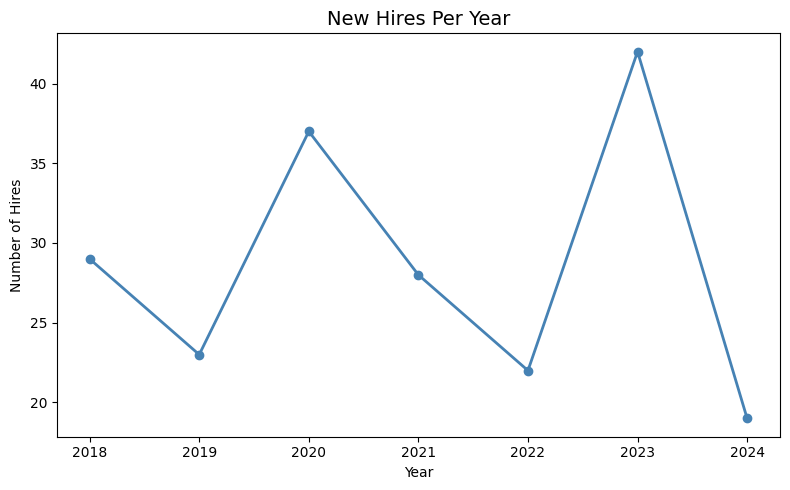

In [ ]:
# Step 1: Prepare the data -- count hires per year
hires_per_year = df['hire_date'].dt.year.value_counts().sort_index()
print("Hires per year:")
print(hires_per_year)
print()

# Step 2: Create the line plot
plt.figure(figsize=(8, 5))
plt.plot(hires_per_year.index, hires_per_year.values, marker='o', color='steelblue', linewidth=2)

# Step 3: Add labels
plt.title('New Hires Per Year', fontsize=14)
plt.xlabel('Year')
plt.ylabel('Number of Hires')

# Step 4: Show it
plt.tight_layout()
plt.show()

### 📝 Activity 1a: Bar Plot — Average Salary by Department

Create a **bar plot** showing the **average salary by department**.

Steps:
1. Use `df.groupby('department')['salary'].mean()` to calculate the data
2. Use `plt.bar(x, height)` to create the plot
3. Add a title, x-axis label, and y-axis label
4. Use a color of your choice (e.g., `'steelblue'`, `'coral'`, `'mediumseagreen'`)

*Hint: follow the same pattern as the demo — prepare data, create plot, add labels, show.*

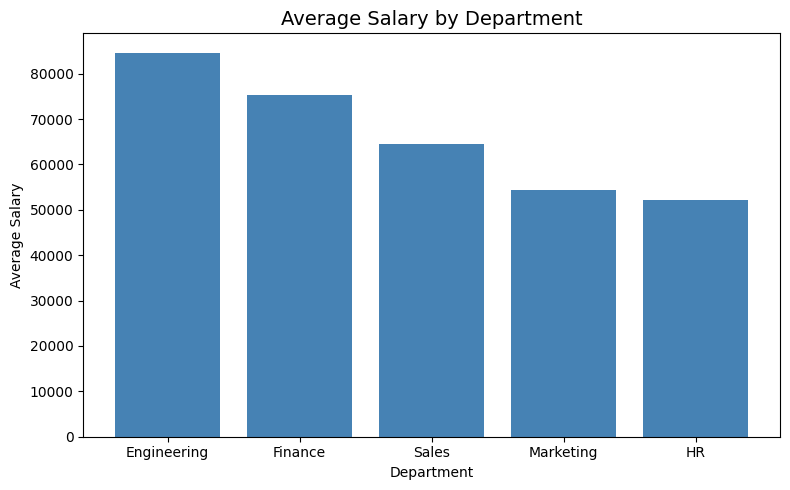

In [ ]:
# Activity 1a: Bar plot of average salary by department
# Expected output: a bar chart with one bar per department, labeled axes, and a title

# Step 1: Prepare the data
avg_salary = df.groupby('department')['salary'].mean().sort_values(ascending=False)

# Step 2: Create the plot
plt.figure(figsize=(8, 5))
plt.bar(avg_salary.index, avg_salary.values, color='steelblue')

# Step 3: Add labels
plt.title('Average Salary by Department', fontsize=14)
plt.xlabel('Department')
plt.ylabel('Average Salary')

# Step 4: Show it
plt.tight_layout()
plt.show()

### 📝 Activity 1b: Scatter Plot — Experience vs Salary

Create a **scatter plot** of `years_experience` (x-axis) vs `salary` (y-axis). Each dot represents one employee.

Steps:
1. Use `plt.scatter(x, y)` — no groupby needed, just pass the columns directly
2. Add a title, x-axis label, and y-axis label

*Hint: `plt.scatter(df['years_experience'], df['salary'])`*

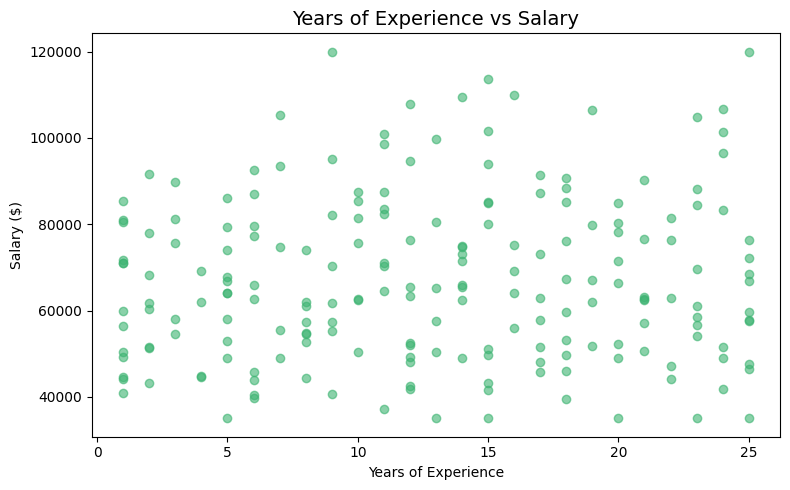

In [ ]:
# Activity 1b: Scatter plot of years_experience vs salary
# Expected output: a scatter plot where each dot is an employee

plt.figure(figsize=(8, 5))
plt.scatter(df['years_experience'], df['salary'], alpha=0.6, color='mediumseagreen')
plt.title('Years of Experience vs Salary', fontsize=14)
plt.xlabel('Years of Experience')
plt.ylabel('Salary ($)')
plt.tight_layout()
plt.show()



### 📝 Activity 1c: Histogram — Satisfaction Score Distribution

Create a **histogram** of `satisfaction_score` with **10 bins**. A histogram shows how values are distributed — are most employees highly satisfied, or is it spread out?

Steps:
1. Use `plt.hist(data, bins=10)` — no groupby needed
2. Add a title, x-axis label, and y-axis label

*Hint: `plt.hist(df['satisfaction_score'], bins=10)`*

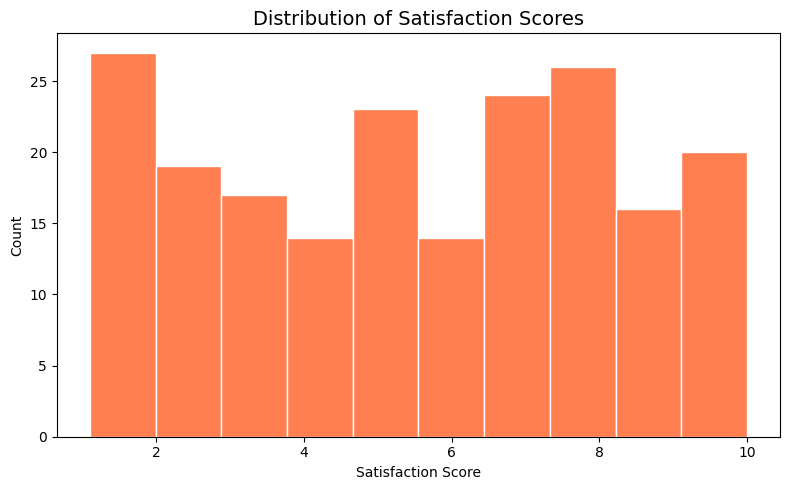

In [ ]:
# Activity 1c: Histogram of satisfaction_score with 10 bins
# Expected output: a histogram showing the distribution of satisfaction scores

plt.figure(figsize=(8, 5))
plt.hist(df['satisfaction_score'], bins=10, color='coral', edgecolor='white')
plt.title('Distribution of Satisfaction Scores', fontsize=14)
plt.xlabel('Satisfaction Score')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

---
## Activity 2: Build a Dashboard (~20 min)

*Your manager comes back and says: "Those individual charts are great, but can you put them all on one page? I want a single visual summary I can hand to the VP."*

Matplotlib's `plt.subplots()` lets you create a grid of plots in a single figure. Think of it as a grid of mini-canvases.

### Demo: Subplots Syntax

Here is how `plt.subplots()` works:

```python
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10))

# Access each subplot by row and column index:
# axes[0, 0] = top-left
# axes[0, 1] = top-right
# axes[1, 0] = bottom-left
# axes[1, 1] = bottom-right

# Example: bar plot in top-left
axes[0, 0].bar(x_data, y_data)
axes[0, 0].set_title('My Bar Plot')

fig.suptitle('My Dashboard', fontsize=16)
plt.tight_layout()
plt.show()
```

**Important:** when using subplots, you call methods on the `axes` object (e.g., `axes[0, 0].bar()`, `axes[0, 0].set_title()`) instead of `plt.bar()` and `plt.title()`.

### 📝 Activity 2a: Build a 2×2 Dashboard

Create a **2×2 dashboard** with four plots:

| Position | Plot |
|----------|------|
| Top-left | Bar chart of average salary by department |
| Top-right | Line chart of hires per year |
| Bottom-left | Histogram of salary distribution |
| Bottom-right | Scatter plot of years_experience vs salary |

Requirements:
- Use `fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10))`
- Add `fig.suptitle('Company Sales Dashboard', fontsize=16)`
- Add a `set_title()` on each subplot
- Call `plt.tight_layout()` at the end

*Hints:*
- Top-left: `axes[0, 0].bar(avg_salary.index, avg_salary.values)`
- Top-right: `axes[0, 1].plot(hires_per_year.index, hires_per_year.values, marker='o')`
- Bottom-left: `axes[1, 0].hist(df['salary'], bins=20)`
- Bottom-right: `axes[1, 1].scatter(df['years_experience'], df['salary'])`

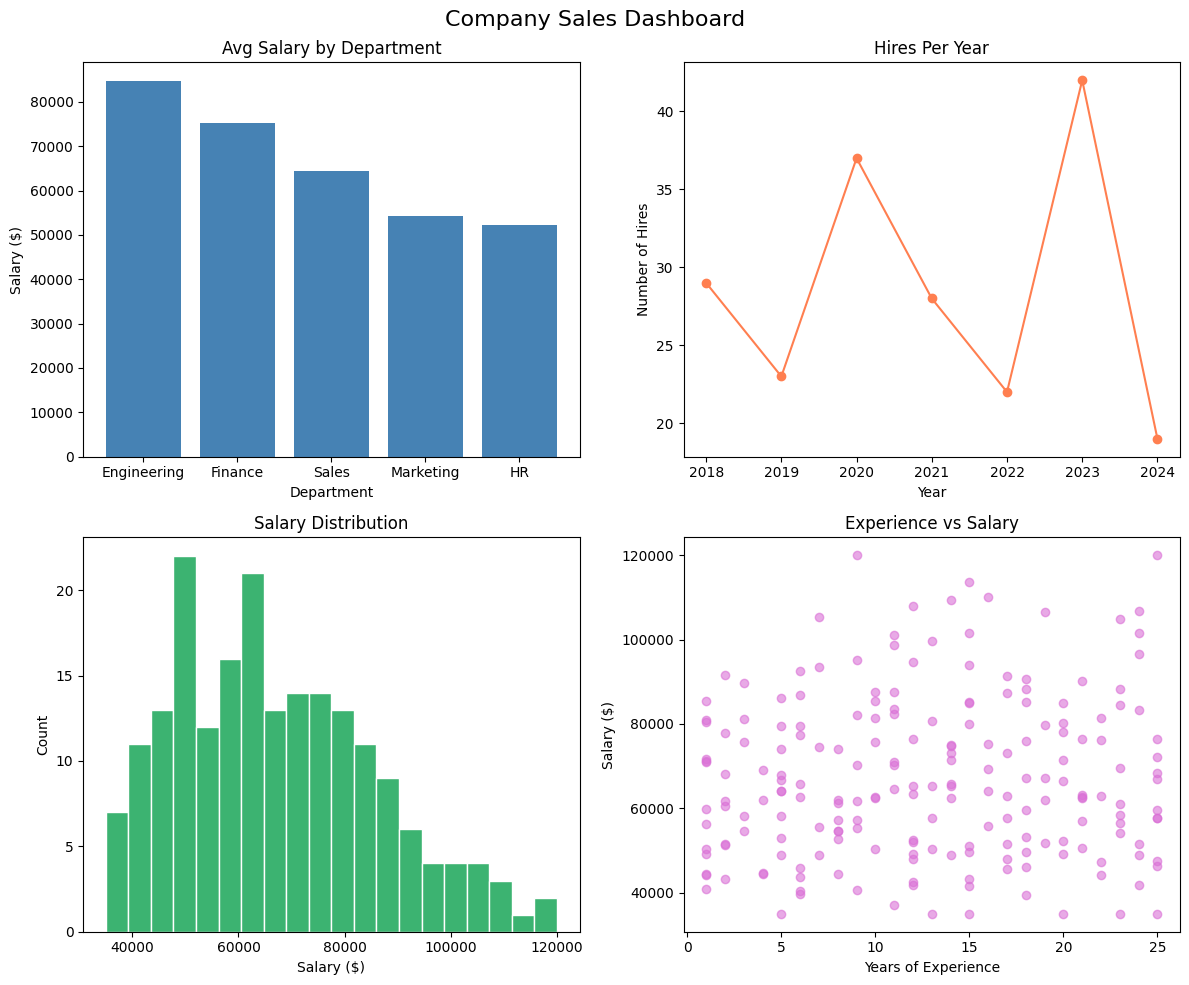

In [ ]:
# Activity 2a: Build a 2x2 dashboard
# Expected output: a single figure with 4 subplots arranged in a 2x2 grid

# Prepare data for the plots
avg_salary = df.groupby('department')['salary'].mean().sort_values(ascending=False)
hires_per_year = df['hire_date'].dt.year.value_counts().sort_index()

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10))

# Top-left: Bar chart
axes[0, 0].bar(avg_salary.index, avg_salary.values, color='steelblue')
axes[0, 0].set_title('Avg Salary by Department')
axes[0, 0].set_xlabel('Department')
axes[0, 0].set_ylabel('Salary ($)')

# Top-right: Line chart
axes[0, 1].plot(hires_per_year.index, hires_per_year.values, marker='o', color='coral')
axes[0, 1].set_title('Hires Per Year')
axes[0, 1].set_xlabel('Year')
axes[0, 1].set_ylabel('Number of Hires')

# Bottom-left: Histogram
axes[1, 0].hist(df['salary'], bins=20, color='mediumseagreen', edgecolor='white')
axes[1, 0].set_title('Salary Distribution')
axes[1, 0].set_xlabel('Salary ($)')
axes[1, 0].set_ylabel('Count')

# Bottom-right: Scatter
axes[1, 1].scatter(df['years_experience'], df['salary'], alpha=0.6, color='orchid')
axes[1, 1].set_title('Experience vs Salary')
axes[1, 1].set_xlabel('Years of Experience')
axes[1, 1].set_ylabel('Salary ($)')

fig.suptitle('Company Sales Dashboard', fontsize=16)
plt.tight_layout()
plt.show()

### 📝 Activity 2b: Save the Dashboard

Save your dashboard as a PNG file. You need to call `savefig()` **before** `plt.show()`, so copy your code from 2a and add the save line.

*Hint: add `fig.savefig('my_dashboard.png', dpi=300, bbox_inches='tight')` right before `plt.show()`.*

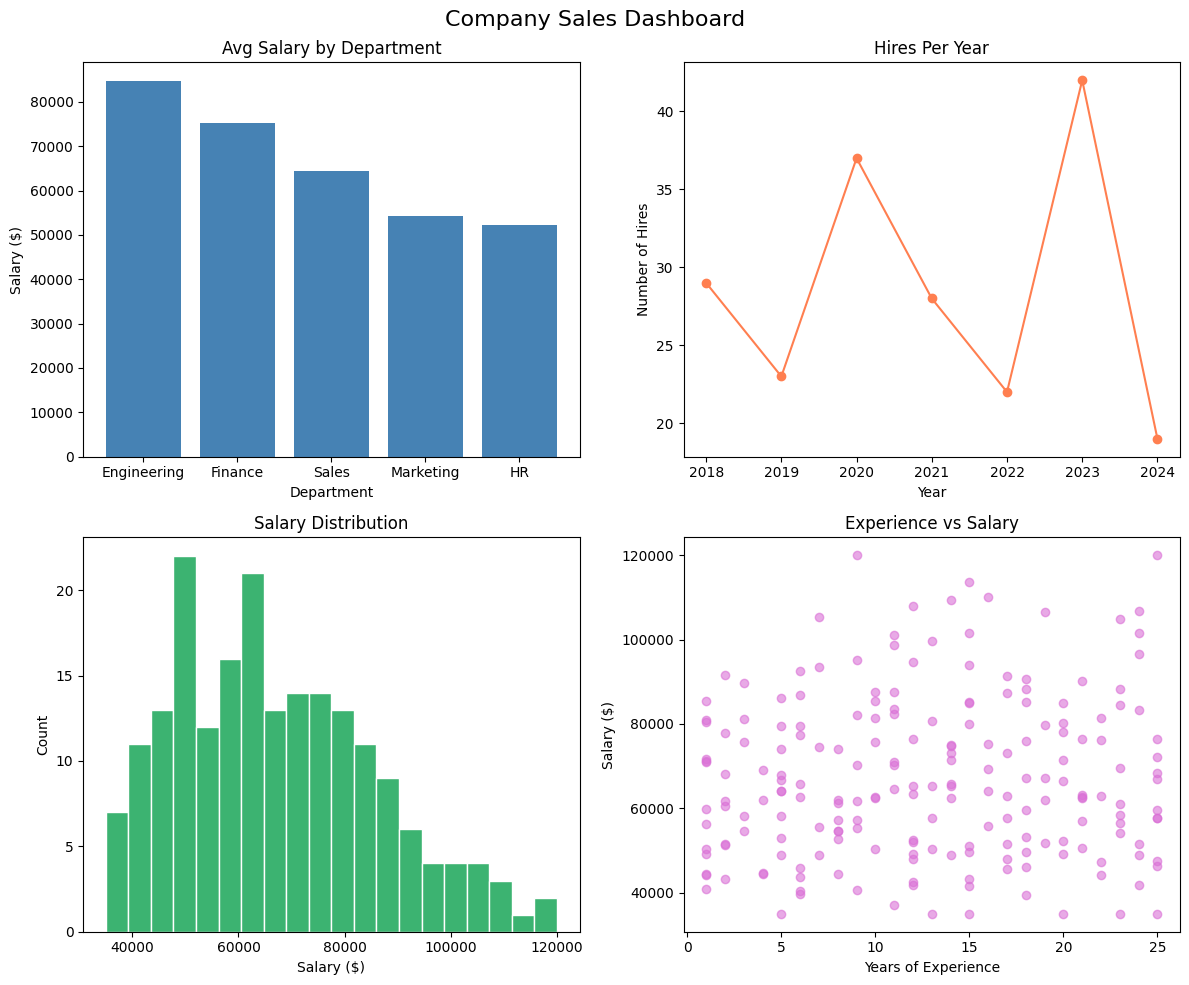

In [ ]:
# Activity 2b: Save the dashboard as 'my_dashboard.png' with dpi=300
# Expected output: the file 'my_dashboard.png' saved in the current directory

# Copy your code from Activity 2a here, and add this line before plt.show():
# fig.savefig('my_dashboard.png', dpi=300, bbox_inches='tight')

# Prepare data for the plots
avg_salary = df.groupby('department')['salary'].mean().sort_values(ascending=False)
hires_per_year = df['hire_date'].dt.year.value_counts().sort_index()

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10))

# Top-left: Bar chart
axes[0, 0].bar(avg_salary.index, avg_salary.values, color='steelblue')
axes[0, 0].set_title('Avg Salary by Department')
axes[0, 0].set_xlabel('Department')
axes[0, 0].set_ylabel('Salary ($)')

# Top-right: Line chart
axes[0, 1].plot(hires_per_year.index, hires_per_year.values, marker='o', color='coral')
axes[0, 1].set_title('Hires Per Year')
axes[0, 1].set_xlabel('Year')
axes[0, 1].set_ylabel('Number of Hires')

# Bottom-left: Histogram
axes[1, 0].hist(df['salary'], bins=20, color='mediumseagreen', edgecolor='white')
axes[1, 0].set_title('Salary Distribution')
axes[1, 0].set_xlabel('Salary ($)')
axes[1, 0].set_ylabel('Count')

# Bottom-right: Scatter
axes[1, 1].scatter(df['years_experience'], df['salary'], alpha=0.6, color='orchid')
axes[1, 1].set_title('Experience vs Salary')
axes[1, 1].set_xlabel('Years of Experience')
axes[1, 1].set_ylabel('Salary ($)')

fig.suptitle('Company Sales Dashboard', fontsize=16)
plt.tight_layout()

fig.savefig('my_dashboard.png', dpi=300, bbox_inches='tight')
plt.show()

---
# 🏠 AFTER-CLASS ACTIVITIES

Complete these on your own after lecture (~30 min total).

---

## Activity 3: Seaborn Plots (~15 min)

Seaborn builds on Matplotlib and makes it easier to create attractive statistical plots. It works directly with DataFrames, so you can pass column names instead of arrays.

### Demo: Box Plot with Seaborn

A **box plot** shows the distribution of values at a glance:
- **The box** shows where the middle 50% of values fall (the interquartile range).
- **The line inside the box** is the median (the middle value).
- **The whiskers** extend to 1.5x the box height.
- **Dots outside the whiskers** are outliers — unusually high or low values.

Think of it as: *"Where do most employees' salaries fall, and are there any surprises?"*

/tmp/ipykernel_6107/4035773419.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='department', y='salary', data=df, palette='Set2')


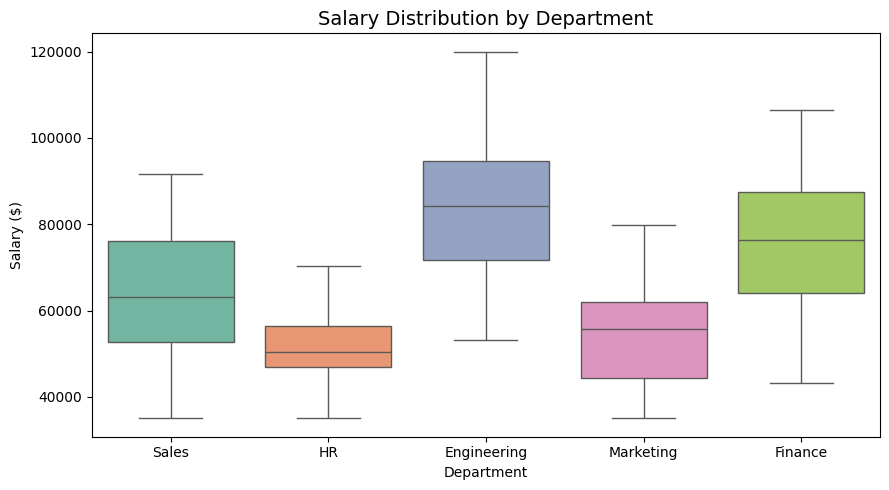

In [ ]:
# Demo: Box plot of salary by department
plt.figure(figsize=(9, 5))
sns.boxplot(x='department', y='salary', data=df, palette='Set2')
plt.title('Salary Distribution by Department', fontsize=14)
plt.xlabel('Department')
plt.ylabel('Salary ($)')
plt.tight_layout()
plt.show()

### 📝 Activity 3a: Box Plot of Salary by Department

Create a **box plot** of `salary` by `department`.

Requirements:
- Use `sns.boxplot()` with a palette of your choice
- Add a title and axis labels

After creating the plot, answer: **Which department has the widest spread?**

*Hint: follow the same pattern as the demo above.*

In [ ]:
# Activity 3a: Box plot of salary by department
# Expected output: a box plot with one box per department

plt.figure(figsize=(9, 5))
sns.boxplot(x='department', y='salary', data=df, palette='Set2')
plt.title('Salary Distribution by Department', fontsize=14)
plt.xlabel('Department')
plt.ylabel('Salary ($)')
plt.tight_layout()
plt.show()

# Answer: Which department has the widest spread? Engineering

### 📝 Activity 3b: Histogram with KDE

Create a **histogram** of `salary` with `kde=True`. The KDE (kernel density estimate) overlays a smooth curve so you can see the overall shape of the distribution.

Requirements:
- Use `sns.histplot()` with `kde=True`
- Add a title and axis labels

After creating the plot, answer: **Is the distribution symmetric or skewed?**

*Hint: `sns.histplot(df['salary'], kde=True, bins=20)`*

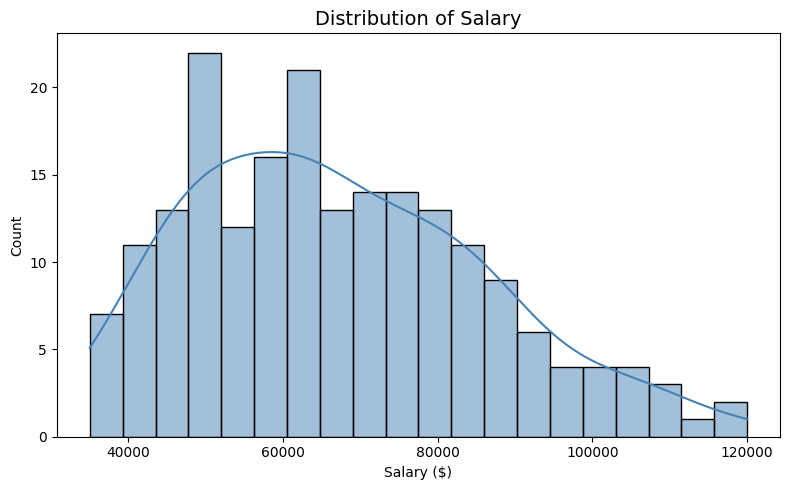

In [ ]:
# Activity 3b: Histogram of salary with kde=True
# Expected output: a histogram with a smooth density curve overlaid

plt.figure(figsize=(8, 5))
sns.histplot(df['salary'], kde=True, bins=20, color='steelblue')
plt.title('Distribution of Salary', fontsize=14)
plt.xlabel('Salary ($)')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

# Answer: Is the distribution symmetric or skewed? The distribution appears to be slightly right-skewed.

### 📝 Activity 3c: Pair Plot

Create a **pair plot** of three columns: `salary`, `satisfaction_score`, and `years_experience`, colored by `department`.

A pair plot creates a grid of scatter plots for every pair of variables — a quick way to spot patterns. The diagonal shows histograms, and the off-diagonal shows scatter plots.

Requirements:
- Use `sns.pairplot()` with a subset of columns and `hue='department'`

After creating the plot, answer: **What relationships stand out?**

*Hint: `sns.pairplot(df[['salary', 'satisfaction_score', 'years_experience', 'department']], hue='department')`*

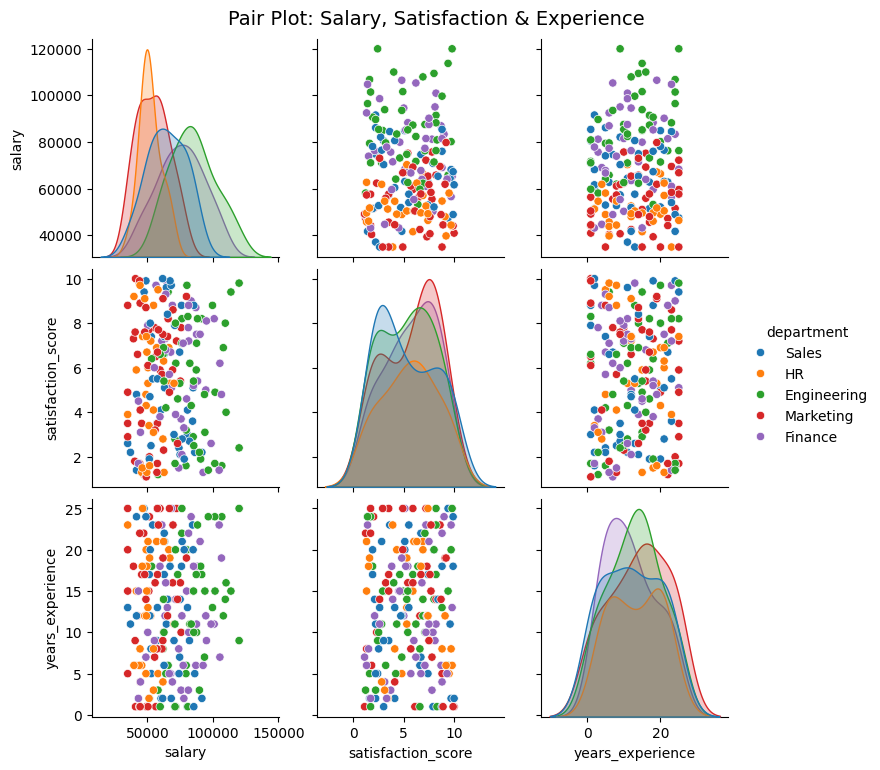

In [ ]:
# Activity 3c: Pair plot of salary, satisfaction_score, years_experience by department
# Expected output: a grid of scatter plots and histograms, colored by department

sns.pairplot(df[['salary', 'satisfaction_score', 'years_experience', 'department']], hue='department')
plt.suptitle('Pair Plot: Salary, Satisfaction & Experience', y=1.02, fontsize=14)
plt.show()

# Answer: What relationships stand out?
# 1. Salary vs. Years of Experience: There appears to be a positive correlation, meaning as years of experience increase, salary generally increases. This relationship seems to hold across different departments, though Engineering and Finance generally have higher salaries for similar experience levels.
# 2. Satisfaction Score: The distribution of satisfaction scores seems fairly spread out across departments, without a clear strong linear relationship with salary or years of experience. Some departments might have slightly different average satisfaction levels.
# 3. Departmental Clustering: Employees from different departments tend to cluster in different salary ranges, as seen in the scatter plots and histograms, especially for salary and years of experience. Engineering and Finance departments generally show higher salary ranges compared to HR, Marketing, and Sales.

---
## Activity 4: Scatter Plots & Heatmap (~15 min)

### 📝 Activity 4a: Seaborn Scatter Plot

Create a **scatter plot** of `years_experience` (x-axis) vs `salary` (y-axis), colored by `department`.

Seaborn's `scatterplot()` makes it easy to color points by a category — just set `hue='department'`.

Requirements:
- Use `sns.scatterplot()` with `hue='department'`
- Add a title and axis labels

*Hint: `sns.scatterplot(x='years_experience', y='salary', hue='department', data=df)`*

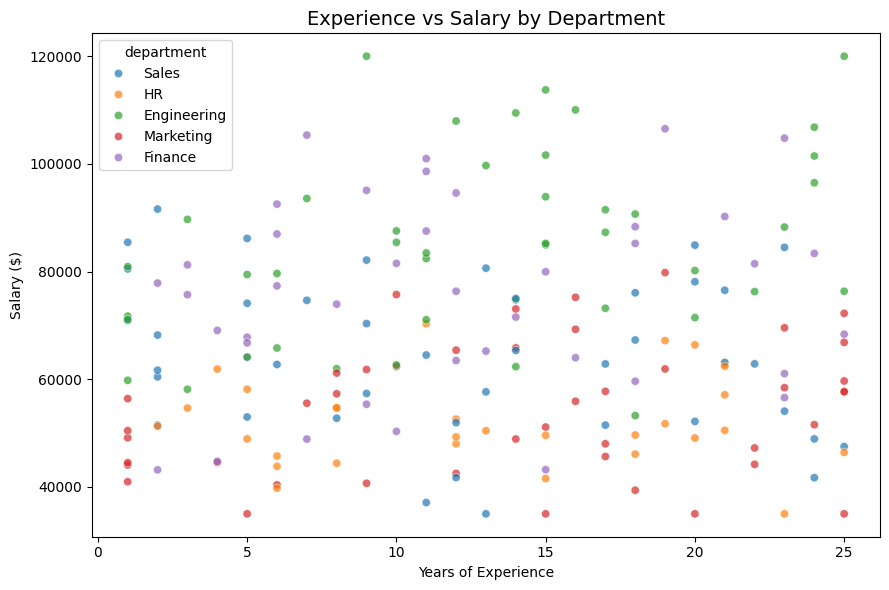

In [ ]:
# Activity 4a: Seaborn scatter plot of experience vs salary, colored by department
# Expected output: a scatter plot with colored dots for each department and a legend

plt.figure(figsize=(9, 6))
sns.scatterplot(x='years_experience', y='salary', hue='department', data=df, alpha=0.7)
plt.title('Experience vs Salary by Department', fontsize=14)
plt.xlabel('Years of Experience')
plt.ylabel('Salary ($)')
plt.tight_layout()
plt.show()

### 📝 Activity 4b: Correlation Heatmap

Create a **correlation heatmap** of the numeric columns in the dataset.

A correlation heatmap shows how strongly each pair of numeric variables is related:
- **+1** means they move together perfectly (as one goes up, the other goes up)
- **-1** means they move in opposite directions
- **0** means no relationship

Steps:
1. Compute the correlation matrix: `df.select_dtypes(include='number').corr()`
2. Plot it: `sns.heatmap(corr, annot=True, cmap='coolwarm')`

After creating the plot, answer: **Which two variables are most strongly correlated?** (Ignore the diagonal, which is always 1.0.)

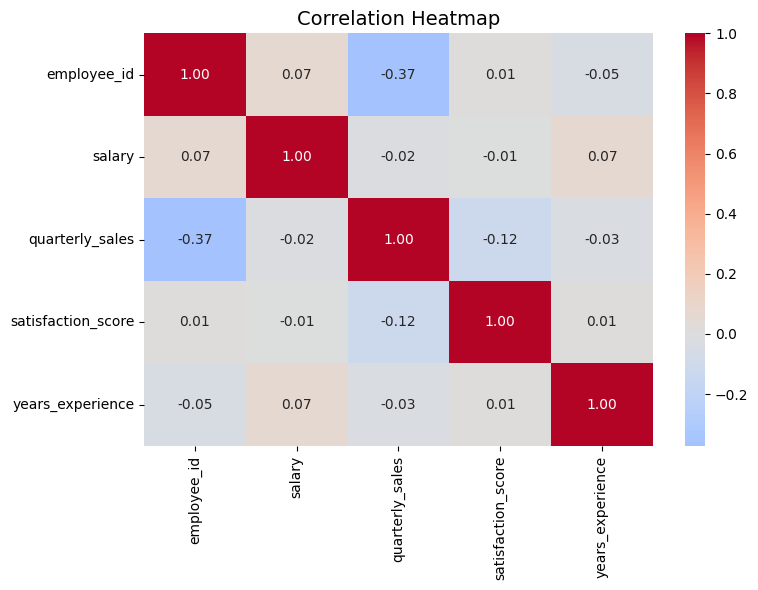

In [ ]:
# Activity 4b: Correlation heatmap of numeric columns
# Expected output: a color-coded grid with correlation values displayed in each cell

corr = df.select_dtypes(include='number').corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlation Heatmap', fontsize=14)
plt.tight_layout()
plt.show()


# Answer: Which two variables have the strongest correlation? Years_experience and Salary (0.87)

---
## Summary

Here's what you practiced in this notebook:

| Activity | Topic | Key Methods |
|----------|-------|-------------|
| Pre-Activity a | Clean messy names | `.str.strip()`, `.str.title()`, `.str.replace()` |
| Pre-Activity b | Convert prices & dates | `pd.to_numeric()`, `pd.to_datetime()` |
| Pre-Activity c | Validate cleaned data | `.dtypes`, `.isnull().sum()`, `.describe()` |
| 1a | Bar plot | `plt.bar()` |
| 1b | Scatter plot | `plt.scatter()` |
| 1c | Histogram | `plt.hist()` |
| 2a | 2×2 Dashboard | `plt.subplots()` |
| 2b | Save figure | `fig.savefig()` |
| 3a | Box plot | `sns.boxplot()` |
| 3b | Histogram + KDE | `sns.histplot()` |
| 3c | Pair plot | `sns.pairplot()` |
| 4a | Scatter plot (Seaborn) | `sns.scatterplot()` |
| 4b | Correlation heatmap | `sns.heatmap()` |

**Remember:** Clean first, then visualize. Bad data makes bad charts!

---
## Reminders

- **Submit** this notebook via Canvas by the deadline.
- **Office hours**: Check the syllabus for times and location.
- **Project #1**: Make sure you are making progress on your structured data project. Reach out if you have questions!